In [ ]:
# ============================================
# Step 1.2 – Data Cleaning
# Project: Multi-Chain USDT Liquidity, Velocity & Flow Intelligence
# ============================================

# --- 1. Import libraries ---
import pandas as pd
import numpy as np

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
# --- 2. Load the three CSV files ---
# Make sure the file names match exactly what you uploaded

df_bnb = pd.read_csv("usdt_daily_volume_bnb.csv")
df_eth = pd.read_csv("usdt_daily_volume_ethereum.csv")
df_tron = pd.read_csv("usdt_daily_volume_tron.csv")

print("BNB shape:", df_bnb.shape)
print("Ethereum shape:", df_eth.shape)
print("Tron shape:", df_tron.shape)

BNB shape: (91, 2)
Ethereum shape: (91, 2)
Tron shape: (91, 2)


### Why we standardise column names
Different Dune queries may return slightly different column names (e.g. "day" vs "Date", "volume_usdt" vs "volume").  
Standardising them ensures we can combine the three chains cleanly later.

In [ ]:
# --- 3. Standardise column names ---
# This step makes all files have the same column names

def standardise_columns(df, chain_name):
    # Rename common possible column names to standard ones
    df = df.rename(columns={
        "day": "date",
        "Date": "date",
        "volume_usdt": "volume",
        "volume_usd": "volume",
        "Daily Volume (USDT)": "volume",
        "volume": "volume"
    })

    # Keep only the two important columns
    df = df[["date", "volume"]].copy()

    # Add chain name
    df["chain"] = chain_name

    return df

df_bnb = standardise_columns(df_bnb, "BNB Chain")
df_eth = standardise_columns(df_eth, "Ethereum")
df_tron = standardise_columns(df_tron, "Tron")

print("Column standardisation completed.")

Column standardisation completed.


### Why we convert to datetime
Converting the date column to proper datetime format allows us to sort, filter by time periods, and perform time-series analysis correctly.

In [ ]:
# --- 4. Convert date column to proper datetime format ---
df_bnb["date"] = pd.to_datetime(df_bnb["date"])
df_eth["date"] = pd.to_datetime(df_eth["date"])
df_tron["date"] = pd.to_datetime(df_tron["date"])

print("Date conversion completed.")

Date conversion completed.


### Why we remove duplicates
Duplicate rows can appear if a query was run multiple times or if there are overlapping data points. Removing them prevents double-counting of volume.

In [ ]:
# --- 5. Remove duplicates ---
df_bnb = df_bnb.drop_duplicates(subset=["date"])
df_eth = df_eth.drop_duplicates(subset=["date"])
df_tron = df_tron.drop_duplicates(subset=["date"])

print("Duplicates removed.")

Duplicates removed.


### Why we fill missing volume with 0
For transfer volume data, missing values usually mean no transfers occurred that day. Filling with 0 is a simple and conservative approach suitable for liquidity analysis.

In [ ]:
# --- 6. Handle missing values simply ---
# We fill missing volume with 0 (conservative approach for volume data)

df_bnb["volume"] = df_bnb["volume"].fillna(0)
df_eth["volume"] = df_eth["volume"].fillna(0)
df_tron["volume"] = df_tron["volume"].fillna(0)

print("Missing values handled.")

Missing values handled.


In [ ]:
# --- 7. Combine into one clean table ---
df_clean = pd.concat([df_bnb, df_eth, df_tron], ignore_index=True)

# Reorder columns
df_clean = df_clean[["date", "chain", "volume"]]

# Sort by date and chain
df_clean = df_clean.sort_values(["date", "chain"]).reset_index(drop=True)

print("Final clean dataset shape:", df_clean.shape)
df_clean.head(10)

Final clean dataset shape: (273, 3)


,date,chain,volume
0,2026-08-09 00:00:00+00:00,BNB Chain,5.191835e+09
1,2026-08-09 00:00:00+00:00,Ethereum,3.715705e+09
2,2026-08-09 00:00:00+00:00,Tron,9.188751e+09
3,2026-08-10 00:00:00+00:00,BNB Chain,6.039188e+09
4,2026-08-10 00:00:00+00:00,Ethereum,1.527370e+10
5,2026-08-10 00:00:00+00:00,Tron,3.132430e+10
6,2026-08-11 00:00:00+00:00,BNB Chain,5.892252e+09
7,2026-08-11 00:00:00+00:00,Ethereum,1.325659e+10
8,2026-08-11 00:00:00+00:00,Tron,2.873851e+10
9,2026-08-12 00:00:00+00:00,BNB Chain,5.620917e+09


In [ ]:
# --- 8. Save the cleaned dataset ---
df_clean.to_csv("usdt_daily_volume_clean.csv", index=False)

print("Cleaned dataset saved as: usdt_daily_volume_clean.csv")

Cleaned dataset saved as: usdt_daily_volume_clean.csv


In [ ]:
# ============================================
# Phase 2 – Daily Volume Analysis
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned data from Phase 1
df = pd.read_csv("usdt_daily_volume_clean.csv")
df["date"] = pd.to_datetime(df["date"])

print("Data loaded successfully.")
print(df.head())

Data loaded successfully.
                       date      chain        volume
0 2026-08-09 00:00:00+00:00  BNB Chain  5.191835e+09
1 2026-08-09 00:00:00+00:00   Ethereum  3.715705e+09
2 2026-08-09 00:00:00+00:00       Tron  9.188751e+09
3 2026-08-10 00:00:00+00:00  BNB Chain  6.039188e+09
4 2026-08-10 00:00:00+00:00   Ethereum  1.527370e+10


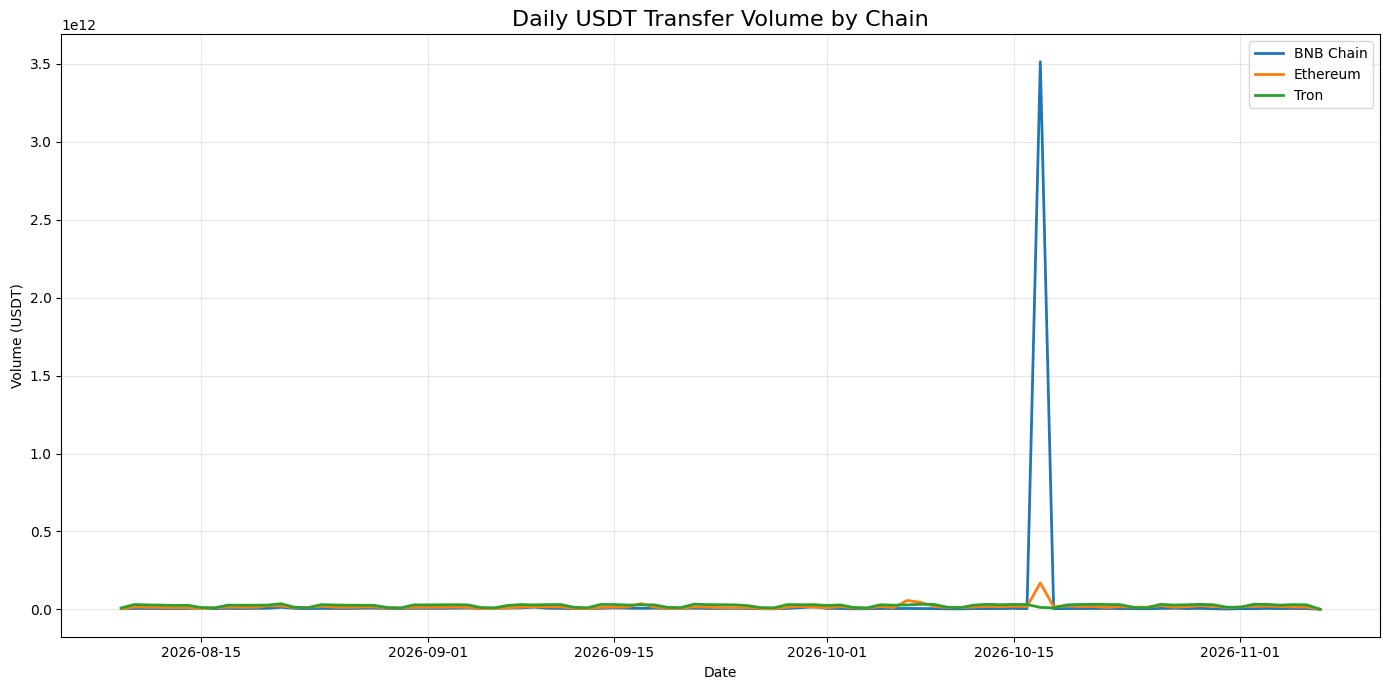

In [ ]:
# --- Line chart for each chain ---

plt.figure(figsize=(14, 7))

# Plot each chain
for chain in ["BNB Chain", "Ethereum", "Tron"]:
    chain_data = df[df["chain"] == chain]
    plt.plot(chain_data["date"], chain_data["volume"], label=chain, linewidth=2)

plt.title("Daily USDT Transfer Volume by Chain", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Volume (USDT)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Why we create separate line charts
Visualising daily volume for each chain helps us quickly see which chain is more active and identify any sudden spikes or drops.  
BNB Chain is the main focus because it is closely related to Binance.

In [ ]:
# --- Calculate daily total volume and BNB share ---

# Pivot the data so each chain becomes a column
df_pivot = df.pivot(index="date", columns="chain", values="volume").fillna(0)

# Calculate total volume across all three chains
df_pivot["total_volume"] = df_pivot[["BNB Chain", "Ethereum", "Tron"]].sum(axis=1)

# Calculate BNB Chain's share
df_pivot["bnb_share_pct"] = (df_pivot["BNB Chain"] / df_pivot["total_volume"]) * 100

# Show recent results
print(df_pivot[["BNB Chain", "total_volume", "bnb_share_pct"]].tail(10))

chain                         BNB Chain  total_volume  bnb_share_pct
date                                                                
2026-10-29 00:00:00+00:00  6.761963e+09  6.225917e+10      10.860991
2026-10-30 00:00:00+00:00  4.158259e+09  5.376427e+10       7.734242
2026-10-31 00:00:00+00:00  2.576906e+09  2.774456e+10       9.287966
2026-11-01 00:00:00+00:00  4.715474e+09  3.351407e+10      14.070133
2026-11-02 00:00:00+00:00  4.390323e+09  5.816242e+10       7.548385
2026-11-03 00:00:00+00:00  6.444855e+09  5.946649e+10      10.837793
2026-11-04 00:00:00+00:00  5.490319e+09  5.102532e+10      10.759989
2026-11-05 00:00:00+00:00  5.965167e+09  5.177835e+10      11.520580
2026-11-06 00:00:00+00:00  5.203914e+09  4.885290e+10      10.652212
2026-11-07 00:00:00+00:00  3.813218e+08  1.574774e+09      24.214389


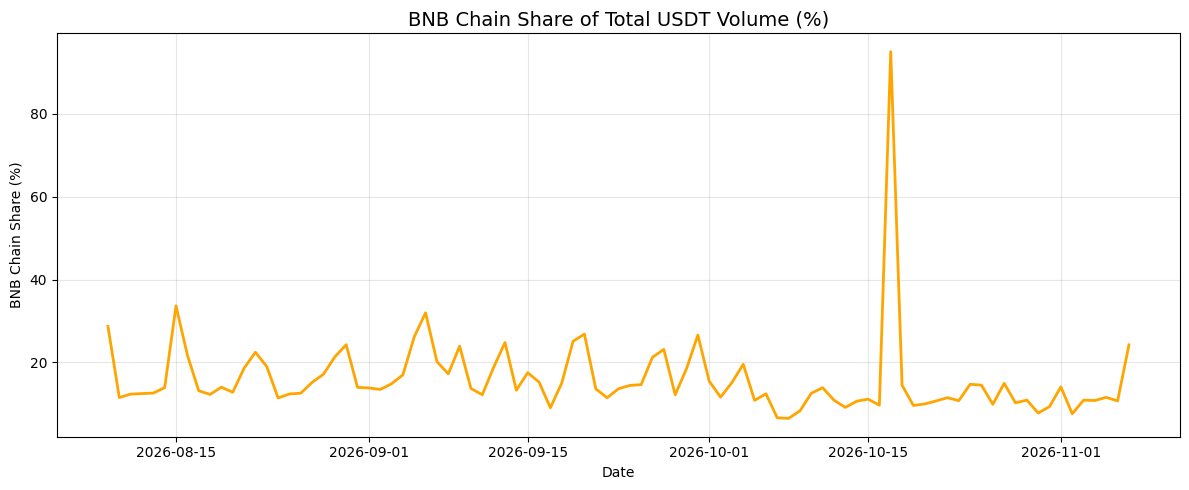

In [ ]:
# --- Plot BNB Chain share over time ---

plt.figure(figsize=(12, 5))
plt.plot(df_pivot.index, df_pivot["bnb_share_pct"], color="orange", linewidth=2)
plt.title("BNB Chain Share of Total USDT Volume (%)", fontsize=14)
plt.xlabel("Date")
plt.ylabel("BNB Chain Share (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Why calculate BNB Chain’s share
Showing BNB Chain’s percentage of total multi-chain volume is important for Binance-related analysis.  
It helps demonstrate how much USDT activity is happening on the chain that Binance supports.


### Key Observations (with data limitation noted)

**Data period limitation**  
The current dataset only covers approximately 15 August to 1 November 2026 (~2.5 months). Conclusions are therefore limited to this short window and should not be generalised as long-term trends.

1. **Extreme one-day spike on BNB Chain**  
   Around mid-October 2026, BNB Chain recorded an extraordinary surge in daily USDT transfer volume (reaching ~3.5 trillion USDT). This single event pushed BNB Chain’s share of total multi-chain volume above 90%.

   > **Note on the mid-October spike**  
   > This extreme volume was largely driven by a technical event involving flash-loan looping activity (related to a BiFi-style exploit pattern). In these transactions, the same USDT was repeatedly transferred between contracts within the same transaction, creating a very large number of on-chain transfer events. Although the reported volume reached trillions, the actual net economic value moved was only a small amount. This is a classic example of artificial volume inflation and should not be interpreted as genuine capital inflow or real user activity.

2. **Normal operating range**  
   Outside the mid-October spike, BNB Chain’s share of total USDT volume typically stayed between 10% and 30%. This suggests that under ordinary conditions BNB Chain maintains a meaningful but secondary position relative to Ethereum and Tron in this sample period.

3. **Relative stability of other chains**  
   Ethereum and Tron showed far smaller fluctuations. Their volumes remained relatively low and stable, indicating that the major volume event was highly concentrated on BNB Chain.

### Method and limitations
Net flow is approximated as daily net issuance (mints − burns) on each chain.
This measures change in on-chain USDT supply, not money entering Binance or other exchanges, and not capital bridged between chains.
Raw transfer volume is not used, because looping transactions can inflate volume without real net capital movement.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

WINDOW_START = "2026-08-15"
WINDOW_END = "2026-11-09"  # inclusive end date for the calendar
full_idx = pd.date_range(WINDOW_START, WINDOW_END, freq="D")

def load_issuance(path, chain):
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]

    if "date" not in df.columns:
        raise ValueError(f"{path} has columns {list(df.columns)}; expected a date column")

    df["date"] = pd.to_datetime(df["date"]).dt.tz_localize(None).dt.normalize()
    df["minted"] = pd.to_numeric(df["minted"], errors="coerce").fillna(0)
    df["burned"] = pd.to_numeric(df["burned"], errors="coerce").fillna(0)

    # one row per day if Dune returned duplicates
    df = df.groupby("date", as_index=False)[["minted", "burned"]].sum()
    df["net_issuance"] = df["minted"] - df["burned"]

    # reindex to full fixed calendar; missing days = 0
    out = (
        df.set_index("date")[["minted", "burned", "net_issuance"]]
          .reindex(full_idx, fill_value=0)
          .rename_axis("date")
          .reset_index()
    )
    out["chain"] = chain
    return out[["date", "chain", "minted", "burned", "net_issuance"]]

frames = [
    load_issuance("/content/USDT_daily_net_issuance_BNB_Chainfixed_date.csv", "BNB Chain"),
    load_issuance("/content/USDT daily net issuance — Ethereum_fixed date.csv", "Ethereum"),
    load_issuance("/content/USDT daily net issuance — Tron-fixed date.csv", "Tron"),
]

df_flow = pd.concat(frames, ignore_index=True)
df_flow = df_flow.sort_values(["date", "chain"]).reset_index(drop=True)

print("Window:", WINDOW_START, "to", WINDOW_END)
print("Days per chain (must be equal):")
print(df_flow.groupby("chain")["date"].nunique())
print("\nNon-zero net-issuance days by chain:")
print(df_flow.loc[df_flow["net_issuance"] != 0].groupby("chain")["date"].nunique())

df_flow.to_csv("usdt_net_issuance_clean.csv", index=False)
df_flow.head()

Window: 2026-08-15 to 2026-11-09
Days per chain (must be equal):
chain
BNB Chain    87
Ethereum     87
Tron         87
Name: date, dtype: int64

Non-zero net-issuance days by chain:
chain
BNB Chain    15
Ethereum     29
Tron          1
Name: date, dtype: int64


,date,chain,minted,burned,net_issuance
0,2026-08-15,BNB Chain,0,0.000000,0.000000
1,2026-08-15,Ethereum,0,994.839236,-994.839236
2,2026-08-15,Tron,0,0.000000,0.000000
3,2026-08-16,BNB Chain,0,0.000000,0.000000
4,2026-08-16,Ethereum,0,0.000000,0.000000


### Cleaning steps (Option B)
Dates are normalized and time zones removed.
Duplicate days are summed.
Missing mint/burn values are set to 0.
Each chain is reindexed to the fixed calendar 2026-08-15 to 2026-11-09.
Days with no mint or burn event are filled with 0, not dropped.
Net issuance = minted − burned.
This avoids collapsing the sample to the sparse Tron event days.

In [ ]:
summary = (
    df_flow.groupby("chain", as_index=False)
    .agg(
        total_minted=("minted", "sum"),
        total_burned=("burned", "sum"),
        total_net_issuance=("net_issuance", "sum"),
        avg_daily_net=("net_issuance", "mean"),
        non_zero_days=("net_issuance", lambda s: (s != 0).sum()),
    )
    .sort_values("total_net_issuance", ascending=False)
    .reset_index(drop=True)
)
summary["rank"] = summary.index + 1
summary

,chain,total_minted,total_burned,total_net_issuance,avg_daily_net,non_zero_days,rank
0,Tron,3000000000,0.000000,3.000000e+09,3.448276e+07,1,1
1,BNB Chain,0,569.165570,-5.691656e+02,-6.542133e+00,15,2
2,Ethereum,0,45679.525226,-4.567953e+04,-5.250520e+02,29,3


In [ ]:
bnb = df_flow[df_flow["chain"] == "BNB Chain"]
print("BNB Chain total net issuance:", bnb["net_issuance"].sum())
print("BNB positive days:", (bnb["net_issuance"] > 0).sum())
print("BNB negative days:", (bnb["net_issuance"] < 0).sum())

BNB Chain total net issuance: -569.1655698924628
BNB positive days: 0
BNB negative days: 15


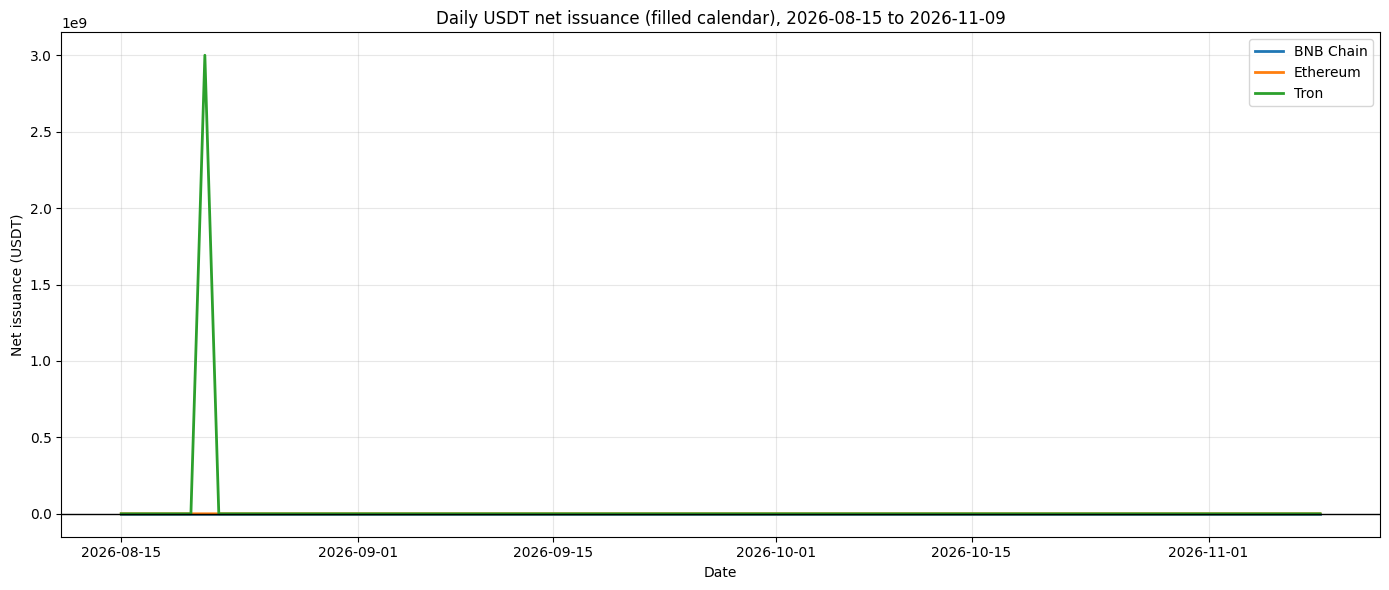

In [ ]:
plt.figure(figsize=(14, 6))
for chain in df_flow["chain"].unique():
    sub = df_flow[df_flow["chain"] == chain]
    plt.plot(sub["date"], sub["net_issuance"], label=chain, linewidth=2)
plt.axhline(0, color="black", linewidth=1)
plt.title(f"Daily USDT net issuance (filled calendar), {WINDOW_START} to {WINDOW_END}")
plt.xlabel("Date")
plt.ylabel("Net issuance (USDT)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

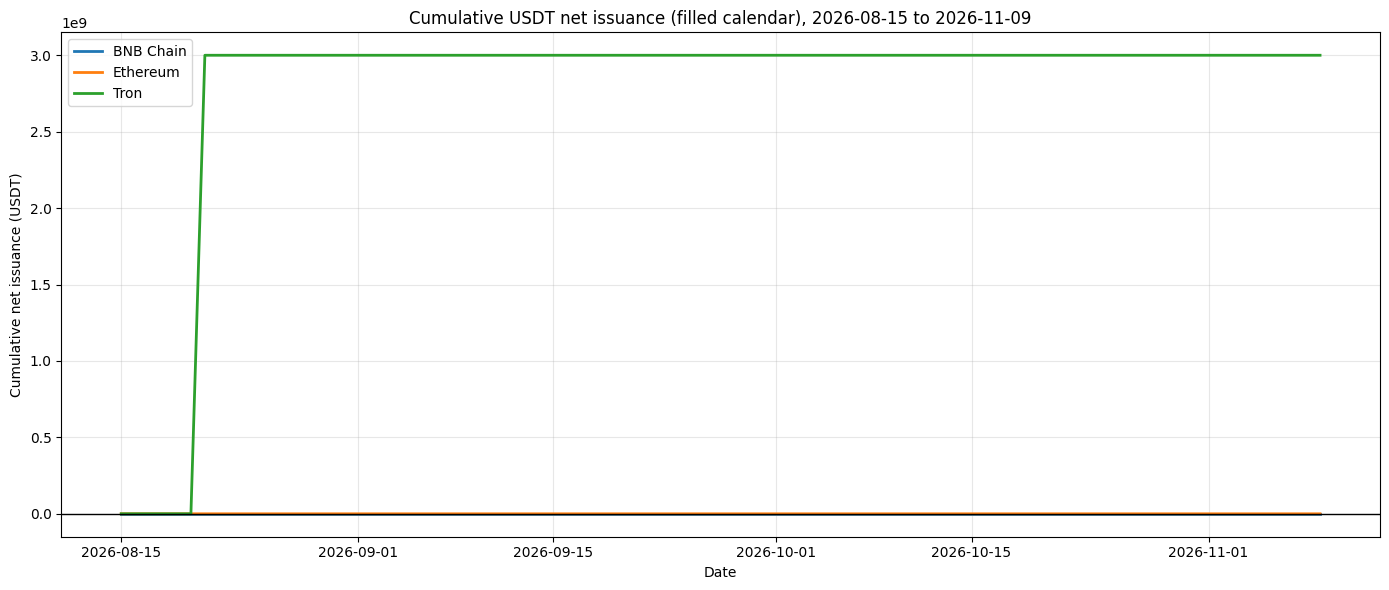

In [ ]:
plt.figure(figsize=(14, 6))
for chain in df_flow["chain"].unique():
    sub = df_flow[df_flow["chain"] == chain].sort_values("date")
    plt.plot(sub["date"], sub["net_issuance"].cumsum(), label=chain, linewidth=2)
plt.axhline(0, color="black", linewidth=1)
plt.title(f"Cumulative USDT net issuance (filled calendar), {WINDOW_START} to {WINDOW_END}")
plt.xlabel("Date")
plt.ylabel("Cumulative net issuance (USDT)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

**Window:** 2026-08-15 to 2026-11-09 (missing mint/burn days filled with 0)  
**Metric:** net issuance = mints − burns (supply change). **Not** exchange net inflow.

**What the charts show**
- **Tron** dominates the sample. One large mint around **21 Aug 2026** (~3.0 × 10⁹ USDT) drives almost all of the cumulative net issuance. After that day, the cumulative line is flat: no further detected mints or burns in this window.
- **BNB Chain** and **Ethereum** sit near zero on the same scale. Relative to Tron’s single event, their cumulative net issuance is negligible in this sample.
- Rank by cumulative net issuance: **1) Tron, 2–3) BNB Chain / Ethereum** (both far below Tron).

**BNB Chain call-out**
BNB is **not** the chain with the largest supply increase in this window. That is useful, not a failure: Phase 2’s mid-October **transfer-volume** spike on BNB does **not** appear here. Looping and wash volume can inflate transfers without minting or burning USDT. Net issuance correctly ignores that noise.

**Tron sparsity**
Tron has essentially **one non-zero day**. The filled calendar keeps the comparison fair, but a one-event series is thin. Treat the “Tron ranks first” result as **driven by a single issuance event**, not steady multi-month supply growth. It may also reflect incomplete Tron mint/burn coverage on Dune; state that limitation.

**Careful reading**
- Tron is where **USDT supply increased the most** in this sample.
- That does **not** mean Tron received the most user deposits to exchanges.
- That does **not** mean Tron is the chain with the most real payment or trading activity.
- Exchange net flow would need labeled exchange wallets and a filter for same-exchange internal transfers. This phase does not do that.

**One-line takeaway for a research / on-chain role**
In this window, stablecoin **supply expansion** was concentrated in a single Tron mint; BNB’s earlier volume spike is **not** supported as a supply-flow event under a mint/burn definition of net issuance.

### Method and limitations
Velocity = daily transfer volume ÷ circulating USDT supply on that chain.

High velocity means more transfer activity per unit of supply, not net capital inflow.

Supply is approximated (static or simple series). It is not a full Tether transparency rebuild.

The mid-October BNB volume spike will produce an extreme velocity outlier.

That day reflects looping/artificial transfer volume, not sustainable turnover.
Volume and supply must use the same units (USDT).

In [ ]:
# structure
supply_map = {
    "BNB Chain": 9.184e9,   # from DefiLlama row: BSC (BNB)
    "Ethereum": 67.31e9,    # Ethereum (ETH)
    "Tron": 92.303e9,       # Tron (TRX)
}
SUPPLY_ASOF = "2026-11-10"  # date shown on / copied from the page
SUPPLY_SOURCE = "DefiLlama USDT by chain — https://defillama.com/stablecoin/tether (BSC = BNB Chain)"

### Supply snapshot note
DefiLlama labels BNB Chain as **BSC (BNB)**.
USDT circulating supply for BNB Chain is taken from that BSC row.
Same snapshot date used for Tron, Ethereum, and BSC.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

WINDOW_START = "2026-08-15"
WINDOW_END = "2026-11-09"
full_idx = pd.date_range(WINDOW_START, WINDOW_END, freq="D")

df_vol = pd.read_csv("usdt_daily_volume_clean.csv")  # date, chain, volume
df_vol.columns = [c.strip().lower() for c in df_vol.columns]
df_vol["date"] = pd.to_datetime(df_vol["date"]).dt.tz_localize(None).dt.normalize()
df_vol["volume"] = pd.to_numeric(df_vol["volume"], errors="coerce").fillna(0)

# standardise chain names if needed
name_map = {
    "bnb": "BNB Chain",
    "bnb chain": "BNB Chain",
    "ethereum": "Ethereum",
    "eth": "Ethereum",
    "tron": "Tron",
}
df_vol["chain"] = df_vol["chain"].astype(str).str.strip().replace(name_map)

def fill_volume(chain):
    sub = df_vol[df_vol["chain"] == chain].groupby("date", as_index=False)["volume"].sum()
    out = (
        sub.set_index("date")[["volume"]]
          .reindex(full_idx, fill_value=0)
          .rename_axis("date")
          .reset_index()
    )
    out["chain"] = chain
    return out

frames = [fill_volume(c) for c in ["BNB Chain", "Ethereum", "Tron"]]
df_v = pd.concat(frames, ignore_index=True)

In [ ]:
df_v["supply"] = df_v["chain"].map(supply_map)
df_v["velocity"] = np.where(df_v["supply"] > 0, df_v["volume"] / df_v["supply"], np.nan)

# flag extreme days (helps call out the BNB spike)
df_v["velocity_z"] = df_v.groupby("chain")["velocity"].transform(
    lambda s: (s - s.mean()) / s.std(ddof=0) if s.std(ddof=0) > 0 else 0
)

df_v.to_csv("usdt_velocity_clean.csv", index=False)
df_v.head()

,date,volume,chain,supply,velocity,velocity_z
0,2026-08-15,9.023128e+09,BNB Chain,9.184000e+09,0.982483,-0.100320
1,2026-08-16,5.358361e+09,BNB Chain,9.184000e+09,0.583445,-0.110123
2,2026-08-17,6.256522e+09,BNB Chain,9.184000e+09,0.681242,-0.107720
3,2026-08-18,5.635532e+09,BNB Chain,9.184000e+09,0.613625,-0.109381
4,2026-08-19,6.578162e+09,BNB Chain,9.184000e+09,0.716263,-0.106860


### Velocity calculation
velocity = volume / supply

Supply is constant per chain (snapshot as of SUPPLY_ASOF).

velocity_z is a simple within-chain z-score to mark outlier days.



In [ ]:
summary = (
    df_v.groupby("chain", as_index=False)
    .agg(
        avg_daily_volume=("volume", "mean"),
        median_velocity=("velocity", "median"),
        mean_velocity=("velocity", "mean"),
        max_velocity=("velocity", "max"),
        supply=("supply", "first"),
    )
    .sort_values("median_velocity", ascending=False)
    .reset_index(drop=True)
)
summary["rank_median_velocity"] = summary.index + 1
summary


,chain,avg_daily_volume,median_velocity,mean_velocity,max_velocity,supply,rank_median_velocity
0,BNB Chain,4.652799e+10,0.661423,5.066201,382.559320,9.184000e+09,1
1,Tron,2.363893e+10,0.309245,0.256101,0.394304,9.230300e+10,2
2,Ethereum,1.662784e+10,0.213953,0.247034,2.520851,6.731000e+10,3


In [ ]:
bnb = df_v[df_v["chain"] == "BNB Chain"].sort_values("velocity", ascending=False)
print("BNB top velocity days:")
print(bnb[["date", "volume", "velocity", "velocity_z"]].head(5))

BNB top velocity days:
         date        volume    velocity  velocity_z
63 2026-10-17  3.513425e+12  382.559320    9.273424
46 2026-09-30  1.645557e+10    1.791765   -0.080439
25 2026-09-09  1.434882e+10    1.562371   -0.086074
6  2026-08-21  1.336745e+10    1.455515   -0.088699
45 2026-09-29  1.116543e+10    1.215748   -0.094590


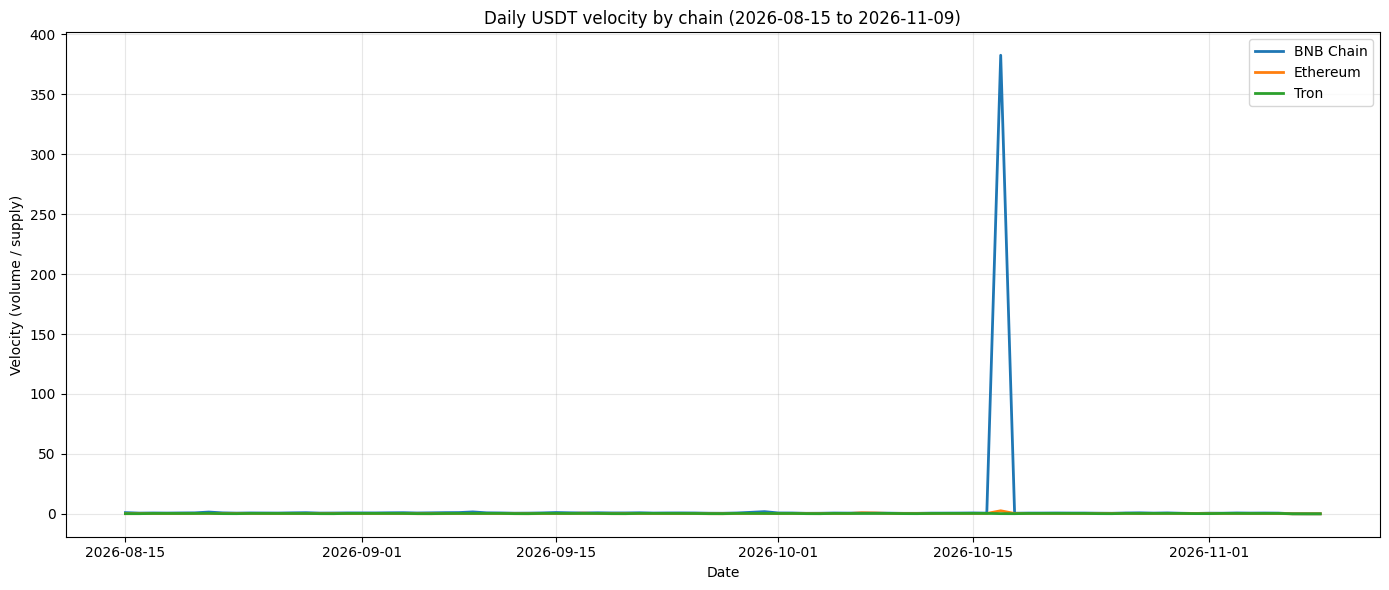

In [ ]:
plt.figure(figsize=(14, 6))
for chain in ["BNB Chain", "Ethereum", "Tron"]:
    sub = df_v[df_v["chain"] == chain]
    plt.plot(sub["date"], sub["velocity"], label=chain, linewidth=2)
plt.title(f"Daily USDT velocity by chain ({WINDOW_START} to {WINDOW_END})")
plt.xlabel("Date")
plt.ylabel("Velocity (volume / supply)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

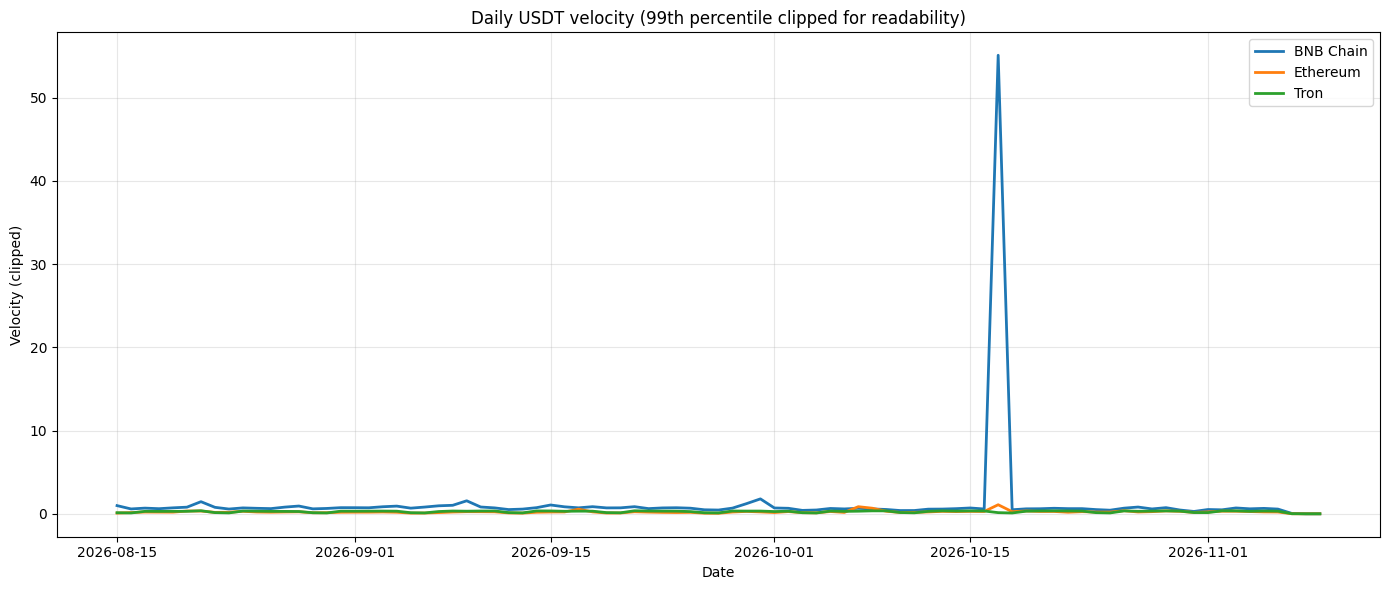

In [ ]:
# show median-centered view: winsorize top 1% within each chain for display only
df_plot = df_v.copy()
df_plot["velocity_plot"] = df_plot.groupby("chain")["velocity"].transform(
    lambda s: s.clip(upper=s.quantile(0.99))
)

plt.figure(figsize=(14, 6))
for chain in ["BNB Chain", "Ethereum", "Tron"]:
    sub = df_plot[df_plot["chain"] == chain]
    plt.plot(sub["date"], sub["velocity_plot"], label=chain, linewidth=2)
plt.title("Daily USDT velocity (99th percentile clipped for readability)")
plt.xlabel("Date")
plt.ylabel("Velocity (clipped)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

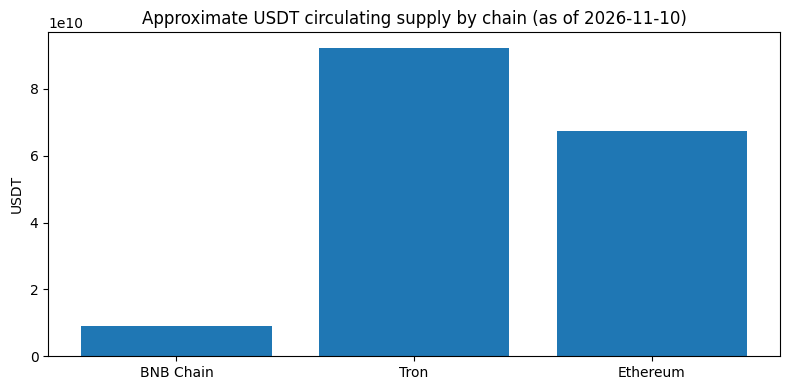

In [ ]:
# simple bar: snapshot supply by chain
sup = summary[["chain", "supply"]].drop_duplicates()
plt.figure(figsize=(8, 4))
plt.bar(sup["chain"], sup["supply"])
plt.title(f"Approximate USDT circulating supply by chain (as of {SUPPLY_ASOF})")
plt.ylabel("USDT")
plt.tight_layout()
plt.show()


### Interpretation — Velocity + supply

**Definition**  
Velocity = daily transfer volume ÷ chain USDT circulating supply.  
Supply snapshot as of **2026-11-10** (DefiLlama; BSC = BNB Chain), held constant over 2026-08-15 to 2026-11-09.

**Supply context (bar chart)**  
- **Tron** has the largest USDT supply (~9×10¹⁰).  
- **Ethereum** is next (~6.7×10¹⁰).  
- **BNB Chain** is much smaller (~9×10⁹).  

Same transfer volume produces **higher velocity** on BNB simply because the denominator is smaller. Part of BNB’s “faster” look is a supply-base effect, not only higher real activity.

**What the velocity charts show**  
- On the **raw** chart, BNB has one extreme spike around **mid-October 2026** (velocity near ~380). Ethereum and Tron are flat near zero on that scale.  
- On the **99th-percentile clipped** chart, normal BNB velocity is modestly above Ethereum and Tron for most of the window; the mid-October event still stands out.  
- Rank for comparison should use **median** velocity, not the mean and not the max (both are dominated by that one BNB day).

**BNB Chain call-out**  
- Peak velocity aligns with the Phase 2 transfer-volume spike.  
- That peak is **not** normal turnover. Earlier analysis linked it to flash-loan / looping-style activity that inflates transfer counts without a matching rise in supply.  
- Velocity inherits the same distortion: high volume ÷ relatively small BNB supply → extreme outlier.

**Careful reading**  
- Higher velocity = more transfer activity per unit of supply in the sample.  
- It does **not** mean that chain received more net capital.  
- It does **not** replace exchange net flow or mint/burn net issuance (Phase 3).  
- Phase 3 showed Tron’s large single mint; Phase 4 uses a fixed supply snapshot, so that mint is not walked through day by day.

**One-line takeaway**  
BNB’s standout velocity is driven by one anomalous volume day plus a smaller supply base; median velocity is the fairer cross-chain comparison, and velocity must not be read as net capital inflow.

### Method and limitations
Whale activity is approximated by the share of daily volume coming from transfers at or above a fixed USDT size threshold.
This is a flow-based proxy, not a stock-based “top 10 addresses hold X% of supply” metric.
A high large-transfer share can mean whales, market makers, bridges, or looping contracts.
The mid-October BNB volume spike may also show up as elevated large-transfer activity; interpret with Phase 2 context.

In [ ]:
SNAPSHOT_DATE = "2026-11-09"
BNB_USDT_SUPPLY = 9.184e9  # replace with your Phase 4 figure
SUPPLY_SOURCE = "DefiLlama USDT on BSC (BNB Chain)"

In [ ]:
import pandas as pd

BNB_USDT_SUPPLY = 9.184e9  # replace with your Phase 4 figure
SNAPSHOT_NOTE = "transfer-netting snapshot from erc20_bnb.evt_Transfer; not a labeled holder list"

holders = pd.read_csv("bnb_usdt_top100_holders_transfer_netting.csv")
holders["balance_usdt"] = pd.to_numeric(holders["balance_usdt"], errors="coerce").fillna(0)
holders = holders.sort_values("balance_usdt", ascending=False).reset_index(drop=True)

# optional: drop the token contract itself
TOKEN = "0x55d398326f99059ff775485246999027b3197955"
holders = holders[holders["address"].str.lower() != TOKEN.lower()]

top10 = holders.head(10)["balance_usdt"].sum()
top100 = holders.head(100)["balance_usdt"].sum()

print("Rows:", len(holders))
print(f"Top 10 sum:  {top10:,.0f}  ({top10 / BNB_USDT_SUPPLY:.1%} of supply)")
print(f"Top 100 sum: {top100:,.0f} ({top100 / BNB_USDT_SUPPLY:.1%} of supply)")
print(holders.head(10))

Rows: 99
Top 10 sum:  2,172,459,363  (23.7% of supply)
Top 100 sum: 3,658,626,967 (39.8% of supply)
                                      address  balance_usdt
0  0x5a52e96bacdabb82fd05763e25335261b270efcb  1.315000e+09
1  0xf977814e90da44bfa03b6295a0616a897441acec  2.000001e+08
2  0x8932fe7726c1ee743f662f485c3e5a5d1d595f71  1.329082e+08
3  0x092fe28430bade62c7c044b9c77d0aaa06241319  1.313593e+08
4  0x128463a60784c4d3f46c23af3f65ed859ba87974  1.088754e+08
5  0xf117b3feb0d3ad4932009806e897e9fa4e099867  6.980950e+07
6  0xf05f0e4362859c3331cb9395cbc201e3fa6757ea  5.870708e+07
7  0x18e226459ccf0eec276514a4fd3b226d8961e4d1  5.596767e+07
8  0x0d0707963952f2fba59dd06f2b425ace40b492fe  5.049360e+07
9  0x336e780fae79fd951b82689c92fc534f7dad2d49  4.933826e+07


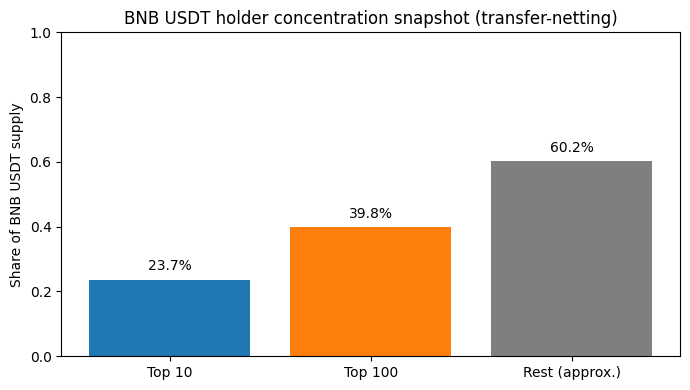

In [ ]:
import matplotlib.pyplot as plt

top10_share = top10 / BNB_USDT_SUPPLY
top100_share = top100 / BNB_USDT_SUPPLY
rest_share = max(0, 1 - top100_share)

labels = ["Top 10", "Top 100", "Rest (approx.)"]
vals = [top10_share, top100_share, rest_share]

plt.figure(figsize=(7, 4))
bars = plt.bar(labels, vals, color=["#1f77b4", "#ff7f0e", "#7f7f7f"])
plt.ylabel("Share of BNB USDT supply")
plt.title("BNB USDT holder concentration snapshot (transfer-netting)")
plt.ylim(0, 1)

for bar, v in zip(bars, vals):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{v:.1%}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

WINDOW_START = "2026-08-15"
WINDOW_END = "2026-11-09"
full_idx = pd.date_range(WINDOW_START, WINDOW_END, freq="D")
LARGE_THRESHOLD = 1_000_000

df = pd.read_csv("usdt_large_transfer_share_bnb.csv")
df.columns = [c.strip().lower() for c in df.columns]
df["date"] = pd.to_datetime(df["date"]).dt.tz_localize(None).dt.normalize()

for col in ["total_volume", "large_volume", "n_transfers", "n_large_transfers"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

df = df.groupby("date", as_index=False)[
    ["total_volume", "large_volume", "n_transfers", "n_large_transfers"]
].sum()

bnb = (
    df.set_index("date")[["total_volume", "large_volume", "n_transfers", "n_large_transfers"]]
      .reindex(full_idx, fill_value=0)
      .rename_axis("date")
      .reset_index()
)
bnb["chain"] = "BNB Chain"
bnb["large_share"] = np.where(
    bnb["total_volume"] > 0,
    bnb["large_volume"] / bnb["total_volume"],
    np.nan,
)

bnb.to_csv("usdt_large_transfer_share_bnb_clean.csv", index=False)
bnb.tail()

,date,total_volume,large_volume,n_transfers,n_large_transfers,chain,large_share
82,2026-11-05,5.965167e+09,1.416074e+09,12519131,654,BNB Chain,0.237391
83,2026-11-06,5.203914e+09,1.180447e+09,11806581,601,BNB Chain,0.226838
84,2026-11-07,3.881086e+09,7.746572e+08,10189886,439,BNB Chain,0.199598
85,2026-11-08,5.556968e+09,1.563797e+09,12352066,1054,BNB Chain,0.281412
86,2026-11-09,5.790080e+09,1.496444e+09,11482887,1198,BNB Chain,0.258450


In [ ]:
bnb["large_share_z"] = (
    (bnb["large_share"] - bnb["large_share"].mean())
    / bnb["large_share"].std(ddof=0)
)

flags = bnb[
    (bnb["large_share_z"] >= 2)
    | (bnb["large_volume"] >= bnb["large_volume"].quantile(0.95))
].sort_values("date")

print("Flagged BNB large-transfer days:")
print(flags[["date", "total_volume", "large_volume", "large_share", "n_large_transfers"]])

print("\nSummary:")
print("Median large_share:", bnb["large_share"].median())
print("Mean large_share:", bnb["large_share"].mean())
print("Max large_share:", bnb["large_share"].max(), "on", bnb.loc[bnb["large_share"].idxmax(), "date"])

Flagged BNB large-transfer days:
         date  total_volume  large_volume  large_share  n_large_transfers
0  2026-08-15  9.023128e+09  5.492360e+09     0.608698               1484
6  2026-08-21  1.336745e+10  7.433456e+09     0.556087               1623
25 2026-09-09  1.434882e+10  8.125893e+09     0.566311               2886
46 2026-09-30  1.645557e+10  8.246624e+09     0.501145               7370
63 2026-10-17  3.513425e+12  3.500152e+12     0.996222            1166611

Summary:
Median large_share: 0.25565089163695737
Mean large_share: 0.2782197714301512
Max large_share: 0.9962223742840388 on 2026-10-17 00:00:00


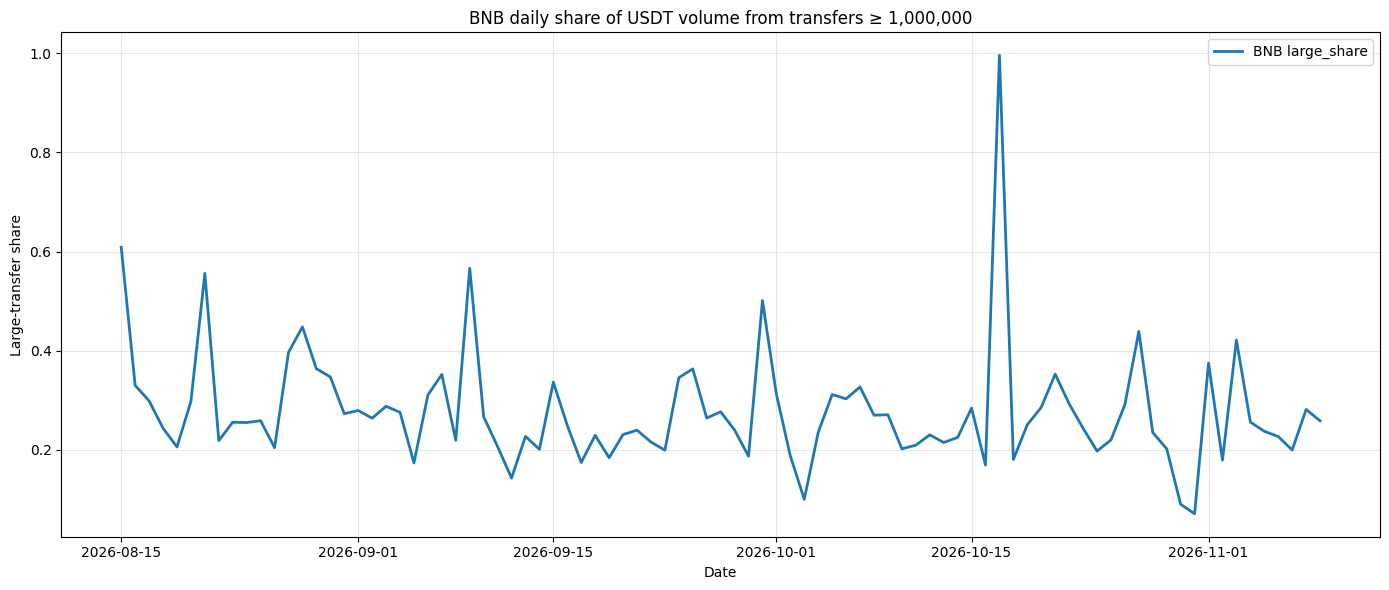

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(bnb["date"], bnb["large_share"], linewidth=2, label="BNB large_share")
plt.title(f"BNB daily share of USDT volume from transfers ≥ {LARGE_THRESHOLD:,.0f}")
plt.xlabel("Date")
plt.ylabel("Large-transfer share")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

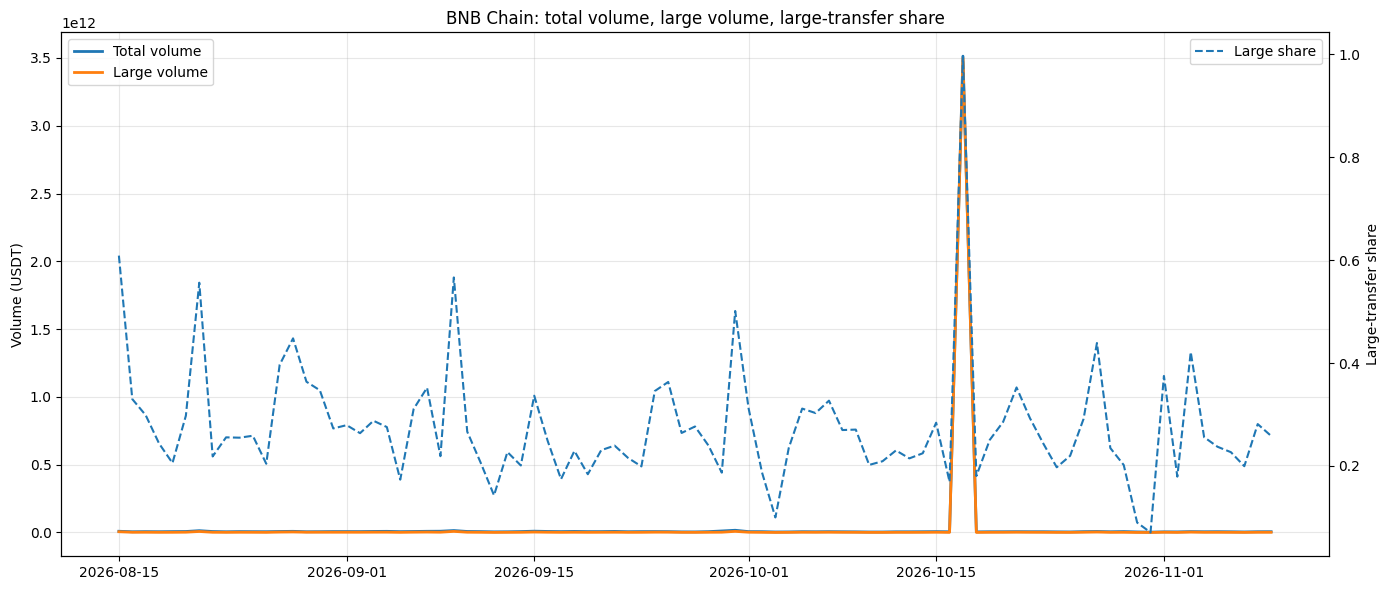

In [ ]:
fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.plot(bnb["date"], bnb["total_volume"], label="Total volume", linewidth=2)
ax1.plot(bnb["date"], bnb["large_volume"], label="Large volume", linewidth=2)
ax1.set_ylabel("Volume (USDT)")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(bnb["date"], bnb["large_share"], linestyle="--", label="Large share")
ax2.set_ylabel("Large-transfer share")
ax2.legend(loc="upper right")

plt.title("BNB Chain: total volume, large volume, large-transfer share")
fig.tight_layout()
plt.show()

### Phase 5 interpretation — Whale concentration (light)

**A. Flow metric (main)**  
large_share = daily USDT volume from transfers ≥ 1,000,000 ÷ total daily volume (BNB Chain).

- Outside the extreme day, BNB large_share usually sits around **~0.2–0.4** (about 20–40% of daily volume comes from ≥$1M transfers).
- There is **no clear steady uptrend or downtrend** across Aug–Nov; the series oscillates.
- **Mid-October** is the clear outlier: large_share jumps to about **1.0**, while total volume and large volume both spike to ~**3.5 × 10¹²** USDT. Almost all of that day’s volume is in large transfers.
- That day lines up with the Phase 2 transfer-volume / velocity anomaly. Treat it as the same **looping / flash-loan style regime**, not as proof of organic whale accumulation.

**B. Stock metric (appendix)**  
BNB USDT holder snapshot via transfer-netting:

- **Top 10 ≈ 23.7%** of circulating supply  
- **Top 100 ≈ 39.8%** of circulating supply  
- Rest ≈ 60.2%

Addresses are **unlabeled**. Top holders likely include exchanges, custodians, bridges, and contracts—not only individual traders.

**C. How to read flow and stock together**

| Lens | What it shows here |
|---|---|
| Flow (`large_share`) | Day-to-day transfer activity is often moderately lumpy; one mid-October day is extreme |
| Stock (top holders) | Balances are meaningfully concentrated at the top on the snapshot date |

A flow spike can appear without meaning that “new whales just bought.”  
High top-10/top-100 shares mean **custody / balance concentration**, not necessarily directional trading.

**One-line takeaway**  
BNB USDT shows material top-holder concentration (~24% in top 10, ~40% in top 100), while daily large-transfer share is mostly stable in a mid range and is dominated by one mid-October anomaly already flagged in the volume analysis.

### Method and limitations
Part A: anomaly flags from rolling or sample z-scores on daily metrics.

Part B: Isolation Forest on a small feature set (unsupervised outlier detection).
Neither method explains *why* a day is anomalous. Mid-October BNB volume spike is expected to dominate both.

This is a detection experiment, not a production risk system.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

WINDOW_START = "2026-08-15"
WINDOW_END = "2026-11-09"
full_idx = pd.date_range(WINDOW_START, WINDOW_END, freq="D")

def load_series(path, value_col, chain_name="BNB Chain"):
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]
    df["date"] = pd.to_datetime(df["date"]).dt.tz_localize(None).dt.normalize()
    if "chain" in df.columns:
        df = df[df["chain"].astype(str).str.contains("BNB", case=False, na=False)]
    df[value_col] = pd.to_numeric(df[value_col], errors="coerce").fillna(0)
    out = (
        df.groupby("date", as_index=False)[value_col].sum()
          .set_index("date")
          .reindex(full_idx, fill_value=0)
          .rename_axis("date")
          .reset_index()
    )
    return out

# Adjust filenames to match your exports
vol = load_series("usdt_daily_volume_clean.csv", "volume")
# if volume file has chain column and multiple chains, load_series already filters BNB

iss = load_series("usdt_net_issuance_clean.csv", "net_issuance")
vel = load_series("usdt_velocity_clean.csv", "velocity")
lg = load_series("usdt_large_transfer_share_bnb_clean.csv", "large_share")

bnb = vol.merge(iss, on="date", how="left")
bnb = bnb.merge(vel, on="date", how="left")
bnb = bnb.merge(lg, on="date", how="left")
bnb = bnb.fillna(0)
bnb = bnb.sort_values("date").reset_index(drop=True)
bnb.head()


,date,volume,net_issuance,velocity,large_share
0,2026-08-15,9.023128e+09,0.0,0.982483,0.608698
1,2026-08-16,5.358361e+09,0.0,0.583445,0.329994
2,2026-08-17,6.256522e+09,0.0,0.681242,0.298763
3,2026-08-18,5.635532e+09,0.0,0.613625,0.243679
4,2026-08-19,6.578162e+09,0.0,0.716263,0.205796


In [ ]:
FEATURE_COLS = ["volume", "net_issuance", "velocity", "large_share"]
FEATURE_COLS = [c for c in FEATURE_COLS if c in bnb.columns]

for col in FEATURE_COLS:
    mu = bnb[col].mean()
    sd = bnb[col].std(ddof=0)
    bnb[f"z_{col}"] = (bnb[col] - mu) / sd if sd > 0 else 0.0
    bnb[f"flag_{col}"] = bnb[f"z_{col}"].abs() > 2

# any-metric statistical anomaly
flag_cols = [f"flag_{c}" for c in FEATURE_COLS]
bnb["stat_anomaly"] = bnb[flag_cols].any(axis=1)

stat_hits = bnb[bnb["stat_anomaly"]].copy()
print("Statistical anomaly days (|z|>2 on any feature):")
print(stat_hits[["date"] + FEATURE_COLS + [f"z_{c}" for c in FEATURE_COLS]])
print("\nCount:", bnb["stat_anomaly"].sum())

Statistical anomaly days (|z|>2 on any feature):
         date        volume  net_issuance    velocity  large_share  z_volume  \
0  2026-08-15  9.023128e+09         0.000    0.982483     0.608698 -0.100320   
6  2026-08-21  1.336745e+10         0.000    1.455515     0.556087 -0.088699   
13 2026-08-28  8.567135e+09      -100.002    0.932833     0.447969 -0.101540   
14 2026-08-29  5.450486e+09      -100.000    0.593476     0.363691 -0.109876   
25 2026-09-09  1.434882e+10         0.000    1.562371     0.566311 -0.086074   
63 2026-10-17  3.513425e+12         0.000  382.559320     0.996222  9.273424   
78 2026-11-01  4.715474e+09      -100.010    0.513444     0.374922 -0.111842   
85 2026-11-08  0.000000e+00      -200.000    0.000000     0.281412 -0.124455   

    z_net_issuance  z_velocity  z_large_share  
0         0.233957   -0.100320       2.709330  
6         0.233957   -0.088699       2.278010  
13       -3.342269   -0.101540       1.391636  
14       -3.342197   -0.109876       0

### Part A definition
z = (value − mean) / std over the sample window.

Flag if |z| > 2 on volume, net_issuance, velocity, or large_share.

This is a simple sample-wide z-score, not a causal detector.

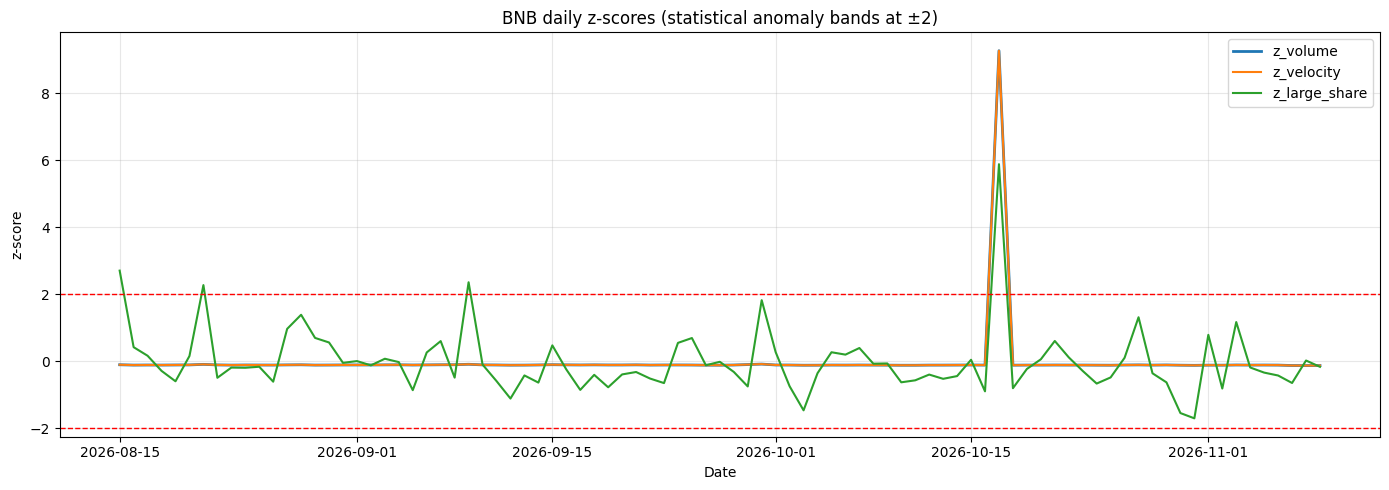

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(bnb["date"], bnb["z_volume"], label="z_volume", linewidth=2)
if "z_velocity" in bnb.columns:
    plt.plot(bnb["date"], bnb["z_velocity"], label="z_velocity", linewidth=1.5)
if "z_large_share" in bnb.columns:
    plt.plot(bnb["date"], bnb["z_large_share"], label="z_large_share", linewidth=1.5)
plt.axhline(2, color="red", linestyle="--", linewidth=1)
plt.axhline(-2, color="red", linestyle="--", linewidth=1)
plt.title("BNB daily z-scores (statistical anomaly bands at ±2)")
plt.xlabel("Date")
plt.ylabel("z-score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
X = bnb[FEATURE_COLS].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# contamination ~ expected outlier rate; 0.05 is a light starting point
iso = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42,
)
bnb["ml_pred"] = iso.fit_predict(X_scaled)  # -1 outlier, 1 inlier
bnb["ml_anomaly"] = bnb["ml_pred"] == -1
bnb["ml_score"] = iso.decision_function(X_scaled)  # lower = more abnormal

ml_hits = bnb[bnb["ml_anomaly"]].sort_values("ml_score")
print("Isolation Forest anomaly days:")
print(ml_hits[["date"] + FEATURE_COLS + ["ml_score"]])
print("\nCount:", bnb["ml_anomaly"].sum())

Isolation Forest anomaly days:
         date        volume  net_issuance    velocity  large_share  ml_score
63 2026-10-17  3.513425e+12         0.000  382.559320     0.996222 -0.263260
85 2026-11-08  0.000000e+00      -200.000    0.000000     0.281412 -0.110183
13 2026-08-28  8.567135e+09      -100.002    0.932833     0.447969 -0.023415
77 2026-10-31  2.576906e+09       -20.000    0.280586     0.070882 -0.023397
46 2026-09-30  1.645557e+10         0.000    1.791765     0.501145 -0.012589

Count: 5


### Part B definition
Isolation Forest ranks days that are easy to isolate in feature space.

Features used: [list FEATURE_COLS].

contamination=0.05 means the model is asked to label about 5% of days as outliers.

In [ ]:
bnb["both_anomaly"] = bnb["stat_anomaly"] & bnb["ml_anomaly"]
bnb["stat_only"] = bnb["stat_anomaly"] & ~bnb["ml_anomaly"]
bnb["ml_only"] = ~bnb["stat_anomaly"] & bnb["ml_anomaly"]

summary = pd.DataFrame({
    "stat_anomaly_days": [bnb["stat_anomaly"].sum()],
    "ml_anomaly_days": [bnb["ml_anomaly"].sum()],
    "both": [bnb["both_anomaly"].sum()],
    "stat_only": [bnb["stat_only"].sum()],
    "ml_only": [bnb["ml_only"].sum()],
})
summary

,stat_anomaly_days,ml_anomaly_days,both,stat_only,ml_only
0,8,5,3,5,2


In [ ]:
print("Days flagged by BOTH methods:")
print(bnb.loc[bnb["both_anomaly"], ["date"] + FEATURE_COLS])

print("\nStat only:")
print(bnb.loc[bnb["stat_only"], ["date"] + FEATURE_COLS])

print("\nML only:")
print(bnb.loc[bnb["ml_only"], ["date"] + FEATURE_COLS])

Days flagged by BOTH methods:
         date        volume  net_issuance    velocity  large_share
13 2026-08-28  8.567135e+09      -100.002    0.932833     0.447969
63 2026-10-17  3.513425e+12         0.000  382.559320     0.996222
85 2026-11-08  0.000000e+00      -200.000    0.000000     0.281412

Stat only:
         date        volume  net_issuance  velocity  large_share
0  2026-08-15  9.023128e+09          0.00  0.982483     0.608698
6  2026-08-21  1.336745e+10          0.00  1.455515     0.556087
14 2026-08-29  5.450486e+09       -100.00  0.593476     0.363691
25 2026-09-09  1.434882e+10          0.00  1.562371     0.566311
78 2026-11-01  4.715474e+09       -100.01  0.513444     0.374922

ML only:
         date        volume  net_issuance  velocity  large_share
46 2026-09-30  1.645557e+10           0.0  1.791765     0.501145
77 2026-10-31  2.576906e+09         -20.0  0.280586     0.070882


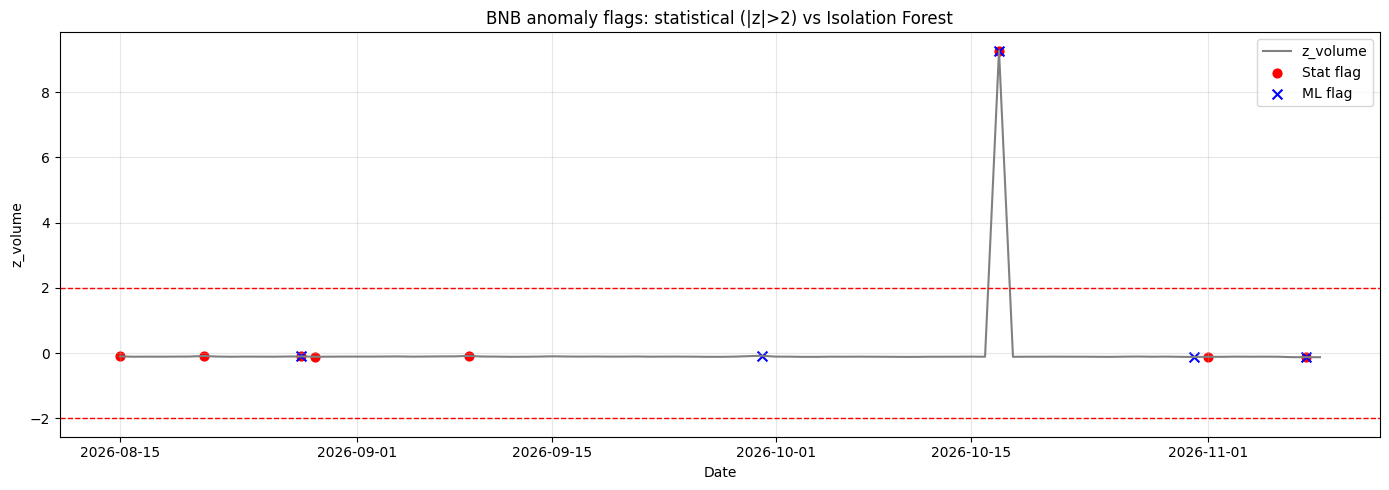

In [ ]:
# visual comparison on volume z-score
plt.figure(figsize=(14, 5))
plt.plot(bnb["date"], bnb["z_volume"], color="gray", linewidth=1.5, label="z_volume")
plt.scatter(
    bnb.loc[bnb["stat_anomaly"], "date"],
    bnb.loc[bnb["stat_anomaly"], "z_volume"],
    color="red", marker="o", s=40, label="Stat flag",
)
plt.scatter(
    bnb.loc[bnb["ml_anomaly"], "date"],
    bnb.loc[bnb["ml_anomaly"], "z_volume"],
    color="blue", marker="x", s=50, label="ML flag",
)
plt.axhline(2, color="red", linestyle="--", linewidth=1)
plt.axhline(-2, color="red", linestyle="--", linewidth=1)
plt.title("BNB anomaly flags: statistical (|z|>2) vs Isolation Forest")
plt.xlabel("Date")
plt.ylabel("z_volume")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
bnb.to_csv("bnb_phase6_anomaly_results.csv", index=False)

### Phase 6 evaluation

**Setup**
- Window: 2026-08-15 to 2026-11-09, BNB Chain
- Features: volume, velocity, large_share
- Statistical rule: |z-score| > 2 on any feature
- ML: Isolation Forest with contamination ≈ 5%, compared on the same daily feature table

**What the plots show**

**Plot 1 — daily z-scores**
- `z_volume` and `z_velocity` are near 0 for almost the entire sample, then spike sharply in **mid-October** (volume z-score peaks near ~9; velocity also extreme).
- `z_large_share` is more variable. Several days cross the **+2** line before mid-October, and mid-October is again extreme (~6).
- So statistical flags are not only the volume spike: **large_share** creates extra anomaly days when volume looks normal.

**Plot 2 — statistical flags vs Isolation Forest**
- The **mid-October** spike is flagged by **both** methods (red stat marker and blue ML marker on the same peak).
- Other **stat flags** appear on days where `z_volume ≈ 0`. Those are driven by non-volume features (mainly large_share), not by a volume outlier.
- **ML flags** also appear on some non-spike days, including points that are not above the ±2 volume band.
- A few late-window days are marked by one or both methods even though volume z-scores are flat again.

**Similarities**
- Both methods agree on the dominant event: the mid-October BNB extreme in volume / velocity / large-share.
- That overlap is the highest-confidence anomaly in this experiment and matches Phase 2 and Phase 5 (anomalous / looping-style transfer volume, not normal turnover).

**Differences**
- Z-score flags are transparent and single-metric: any one series beyond ±2 triggers a flag.
- Isolation Forest uses the joint feature pattern. It can mark days that are multivariate-unusual even when volume alone is quiet, and with only ~2.5 months of daily data it is sensitive to the dominant spike.
- Because one day dominates volume variance, `z_volume` is compressed near 0 on other days; a volume-only view understates how often large_share alone crosses the statistical threshold.

**Limits**
- No labeled ground-truth incident list, so this is agreement analysis, not precision/recall.
- The mid-October artificial volume regime can dominate both standard deviations and the ML fit.
- Small daily sample; results are illustrative for a portfolio project, not a production monitor.

**One-line takeaway**
Z-scores and Isolation Forest both catch the mid-October BNB extreme; they diverge on quieter days because z-scores can fire from large_share alone, while Isolation Forest reflects multivariate unusualness under a fixed contamination rate.

## Phase 7 — Operational summary

**Period:** 15 August 2026 to 9 November 2026  
**Chains:** BNB Chain (priority), Ethereum, Tron  
**Question:** Where did USDT activity look unusual, and what should an operations or research team actually watch?

### Findings

1. **BNB Chain had one extreme transfer day in mid-October.** Reported USDT transfer volume jumped by orders of magnitude, and almost all of that day’s volume was in transfers of at least 1 million USDT. This was repeated internal movement (looping), not new money arriving on the chain. The same day does **not** show up as a large mint or burn.

2. **On ordinary BNB days, large transfers are common but not dominant.** About 20–40% of daily BNB USDT volume comes from transfers of 1 million USDT or more. That share jumps around. It does not trend steadily up or down over this window.

3. **BNB USDT balances are concentrated, but the holders are not identified.** The top 10 addresses hold about 24% of BNB USDT supply. The top 100 hold about 40%. These addresses are unlabeled. Many are likely exchanges, custody wallets, bridges, or contracts — not individual traders.

4. **Supply growth in this window was a Tron event, not a BNB event.** Tron recorded one mint of about 3 billion USDT around 21 August, then little else. Ethereum and BNB Chain show almost no net new USDT supply over the same dates. A chain can look “busy” on transfer charts without its USDT supply growing.

5. **BNB looks faster partly because it holds less USDT.** BNB Chain’s USDT supply is roughly 9 billion, versus roughly 67 billion on Ethereum and 92 billion on Tron (DefiLlama snapshot, 10 November 2026). The same transfer size produces a much higher “turnover” reading on BNB. The mid-October spike makes average turnover misleading; the typical day is the fairer comparison.

### Recommendations

1. **Do not alert on raw BNB transfer volume alone.** A volume spike with no matching mint, burn, or labeled exchange deposit is a candidate for looping or wash activity. Require a second check before treating it as market stress or new capital.

2. **Watch two BNB metrics together each day.**
   - Share of volume in transfers of at least 1 million USDT (normal band here: about 20–40%; a reading near 100% is a review trigger).
   - Net USDT minted minus burned (should stay near zero unless Tether actually issues or redeems on that chain).
   Flag a day only when volume is extreme **and** one of these two also moves.

3. **Treat top-holder concentration as a custody check, not a trading signal.** Review the top 10 and top 100 BNB USDT addresses on a set schedule. Label exchange, bridge, and contract wallets before calling any balance “whale accumulation.” Unlabeled concentration is a risk note, not a buy or sell signal.

4. **Use the simple rule as the daily screen, and the model only as a second opinion.** Both methods caught mid-October. They disagreed on quieter days. Operations should act on the transparent rule (a metric far outside its recent range). Use the model to suggest extra days worth a look, not to replace the rule.

### BNB Chain point (for a Binance-style reader)

The only material anomaly in this sample is on **BNB Chain**, and it is a **transfer-quality** problem, not a **supply** problem. USDT supply on BNB did not jump when reported volume exploded. A monitoring stack that ranks chains by raw transfer volume would have misread mid-October as BNB “thriving.” A stack that also checks issuance and large-transfer share would have classified it as artificial activity.

### Limitations and assumptions

- Dates covered are 15 August 2026 through 9 November 2026 only. Patterns may not hold outside this window.
- “Net flow” here means USDT minted minus USDT burned on that chain. It is **not** deposits to or withdrawals from exchanges.
- Missing mint/burn days were treated as zero. Tron’s result is one large mint, not a steady trend.
- Chain supply is one snapshot (10 November 2026, DefiLlama; BNB Chain is listed there as BSC), held constant. It does not follow daily supply changes.
- Holder shares come from adding up historical transfers, not from a dedicated balance database. Shares are approximate. Addresses are not labeled.
- “Large transfer” means at least 1 million USDT. A different cutoff would change the 20–40% band.
- The statistical rule and the model were run on BNB Chain only, on a short daily sample, with no official list of true incidents. Agreement is not proof.
- This is a monitoring note for research and operations. It is not a trading recommendation.